# HDB Rentals: EDA of `data/auxiliary/sg-mrt-stations.csv`

Station inventory for area-level connectivity. One row is a *(station, line)* pair, not a unique
building: interchanges appear once per line.

Planned stations stay in this table. The 1 km count in `03_feature_rmse.ipynb` uses unique **open**
station names only.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()`
4. Data-quality issues
5. A cleaned analysis frame
6. Lines, status and geography
7. Area-level connectivity features
8. Summary


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA = ROOT / "data"
AUX = DATA / "auxiliary"
CLEANED = ROOT / "cleaned"
OUT = ROOT / "outputs"
OUT_DIR = OUT
CLEANED.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SG_LAT = (1.13, 1.47)
SG_LON = (103.6, 104.1)


def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(dropna=True),
                "unique_pct": 100 * s.nunique(dropna=True) / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out

mrt_raw = pd.read_csv(AUX / "sg-mrt-stations.csv")
print(f"mrt: {mrt_raw.shape}")
mrt_raw.head()


mrt: (243, 8)


,CODE,NAME,STATUS,LATITUDE,LONGITUDE,SUBZONE,PLANNING_AREA,REGION
0,ns10,admiralty mrt station,open,1.441,103.801,woodlands east,woodlands,north region
1,ew9,aljunied mrt station,open,1.316,103.883,aljunied,geylang,central region
2,ns16,ang mo kio mrt station,open,1.370,103.849,cheng san,ang mo kio,north-east region
3,cr11,ang mo kio mrt station,planned,1.370,103.849,cheng san,ang mo kio,north-east region
4,cr2,aviation park mrt station,open,1.370,104.003,changi airport,changi,east region


## 1. Why this table exists

Rental rows have no transport fields. Stations join to flats through `PLANNING_AREA` (from the HDB
crosswalk). This notebook profiles the inventory, derives `LINE` from `CODE`, flags interchanges,
and counts open / planned stations per area. Those area totals are tested in `03_feature_rmse.ipynb`
and do not beat `TOWN`. Walking-distance counts use the coordinates kept here.


## 2. Structure, dtypes and missingness


In [2]:
mrt_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CODE           243 non-null    object 
 1   NAME           243 non-null    object 
 2   STATUS         243 non-null    object 
 3   LATITUDE       243 non-null    float64
 4   LONGITUDE      243 non-null    float64
 5   SUBZONE        243 non-null    object 
 6   PLANNING_AREA  243 non-null    object 
 7   REGION         243 non-null    object 
dtypes: float64(2), object(6)
memory usage: 15.3+ KB


In [3]:
column_profile(mrt_raw)


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
CODE,object,243,100.000,0,0.000,"ns10, ew9, ns16, cr11"
NAME,object,192,79.012,0,0.000,"admiralty mrt station, aljunied mrt station, ang mo kio mrt station, aviation park mrt station"
STATUS,object,2,0.823,0,0.000,"open, planned"
LATITUDE,float64,170,69.959,0,0.000,"1.440689, 1.316389, 1.370017, 1.37"
LONGITUDE,float64,182,74.897,0,0.000,"103.800933, 103.882778, 103.84945, 104.003056"
SUBZONE,object,147,60.494,0,0.000,"woodlands east, aljunied, cheng san, changi airport"
PLANNING_AREA,object,45,18.519,0,0.000,"woodlands, geylang, ang mo kio, changi"
REGION,object,5,2.058,0,0.000,"north region, central region, north-east region, east region"


In [4]:
print("fully duplicated rows:", mrt_raw.duplicated().sum())
print("duplicated CODE:", mrt_raw.duplicated("CODE").sum())
print("duplicated NAME:", mrt_raw.duplicated("NAME").sum(),
      " (expected: interchanges are one row per line)")
print("unique names:", mrt_raw["NAME"].nunique(), "  rows:", len(mrt_raw))


fully duplicated rows: 0
duplicated CODE: 0
duplicated NAME: 51  (expected: interchanges are one row per line)
unique names: 192   rows: 243


## 3. `.describe()`


In [5]:
num_cols = mrt_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in mrt_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

mrt_raw[num_cols].describe().T


numeric    : ['LATITUDE', 'LONGITUDE']
categorical: ['CODE', 'NAME', 'STATUS', 'SUBZONE', 'PLANNING_AREA', 'REGION']


,count,mean,std,min,25%,50%,75%,max
LATITUDE,243.000,1.334,0.041,1.265,1.303,1.328,1.357,1.449
LONGITUDE,243.000,103.832,0.076,103.637,103.783,103.844,103.878,104.003


In [6]:
mrt_raw[cat_cols].describe().T


,count,unique,top,freq
CODE,243,243,ns10,1
NAME,243,192,pasir ris mrt station,3
STATUS,243,2,open,231
SUBZONE,243,147,central subzone,6
PLANNING_AREA,243,45,downtown core,19
REGION,243,5,central region,119


## 4. Data-quality issues


In [7]:
# (a) STATUS is open vs planned — planned stations are not yet usable amenity.
print(mrt_raw["STATUS"].value_counts(), "\n")

# (b) Coordinates.
bad_coords = mrt_raw[
    ~mrt_raw["LATITUDE"].between(*SG_LAT) | ~mrt_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")

# (c) CODE encodes the line as a letter prefix (ns10, ew9, cr11, …).
print("\nCODE examples:", mrt_raw["CODE"].head(8).tolist())


STATUS
open       231
planned     12
Name: count, dtype: int64 

out-of-bounds coordinates: 0

CODE examples: ['ns10', 'ew9', 'ns16', 'cr11', 'cr2', 'js7', 'cc12', 'cc34']


Duplicate `NAME`s are interchanges, not errors. Planned rows stay in the table so area features can
split open vs planned. They are **dropped** when `03_feature_rmse.ipynb` counts unique open MRT
names within 1 km of a block.


## 5. A cleaned analysis frame


In [8]:
def clean_mrt(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["LINE"] = out["CODE"].str.extract(r"^([a-z]+)", expand=False)
    n_lines = out.groupby("NAME")["LINE"].transform("nunique")
    out["IS_INTERCHANGE"] = n_lines.gt(1)
    return out.reset_index(drop=True)


mrt = clean_mrt(mrt_raw)
print(mrt.shape)
print(mrt["LINE"].value_counts())
mrt.head(3)


(243, 10)
LINE
dt     37
cc     34
te     33
ew     33
ns     29
cr     21
ne     17
js     12
je      7
jw      5
cp      4
cg      3
bp      2
de      2
ptc     1
pe      1
stc     1
rts     1
Name: count, dtype: int64


,CODE,NAME,STATUS,LATITUDE,LONGITUDE,SUBZONE,PLANNING_AREA,REGION,LINE,IS_INTERCHANGE
0,ns10,admiralty mrt station,open,1.441,103.801,woodlands east,woodlands,north region,ns,False
1,ew9,aljunied mrt station,open,1.316,103.883,aljunied,geylang,central region,ew,False
2,ns16,ang mo kio mrt station,open,1.370,103.849,cheng san,ang mo kio,north-east region,ns,True


In [9]:
# PLANNING_AREA / REGION spelling vs the HDB crosswalk (shared areas only).
hdb_ref_path = CLEANED / "sg_hdb_block_cleaned.csv"
if hdb_ref_path.exists():
    hdb_ref = pd.read_csv(hdb_ref_path)
    hdb_geo = hdb_ref.drop_duplicates("PLANNING_AREA").set_index("PLANNING_AREA")["REGION"]
    mrt_geo = mrt.drop_duplicates("PLANNING_AREA").set_index("PLANNING_AREA")["REGION"]
    shared = hdb_geo.index.intersection(mrt_geo.index)
    mismatch = (hdb_geo.loc[shared] != mrt_geo.loc[shared]).sum()
    print(f"shared PLANNING_AREA values: {len(shared)}")
    print(f"REGION mismatches on those areas: {mismatch}")
    print("MRT-only planning areas (no HDB housing):",
          sorted(set(mrt["PLANNING_AREA"]) - set(hdb_ref["PLANNING_AREA"])))
else:
    print("run 01_eda_hdb.ipynb first to compare spelling against the HDB crosswalk")


shared PLANNING_AREA values: 31
REGION mismatches on those areas: 0
MRT-only planning areas (no HDB housing): ['boon lay', 'marina east', 'marina south', 'museum', 'newton', 'orchard', 'pioneer', 'river valley', 'singapore river', 'straits view', 'sungei kadut', 'tengah', 'tuas', 'western water catchment']


## 6. Lines, status and geography


STATUS,open,planned
LINE,,
bp,2,0
cc,34,0
cg,2,1
cp,3,1
cr,14,7
de,2,0
dt,37,0
ew,33,0
je,6,1


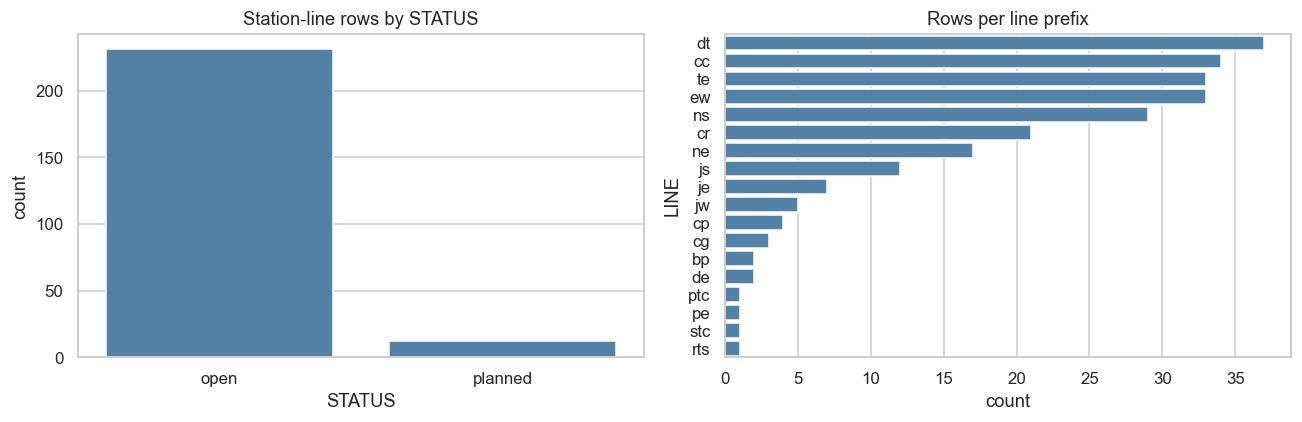

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=mrt, x="STATUS", ax=axes[0], color="steelblue")
axes[0].set_title("Station-line rows by STATUS")
sns.countplot(data=mrt, y="LINE", order=mrt["LINE"].value_counts().index,
              ax=axes[1], color="steelblue")
axes[1].set_title("Rows per line prefix")
plt.tight_layout()
plt.show()

pd.crosstab(mrt["LINE"], mrt["STATUS"])


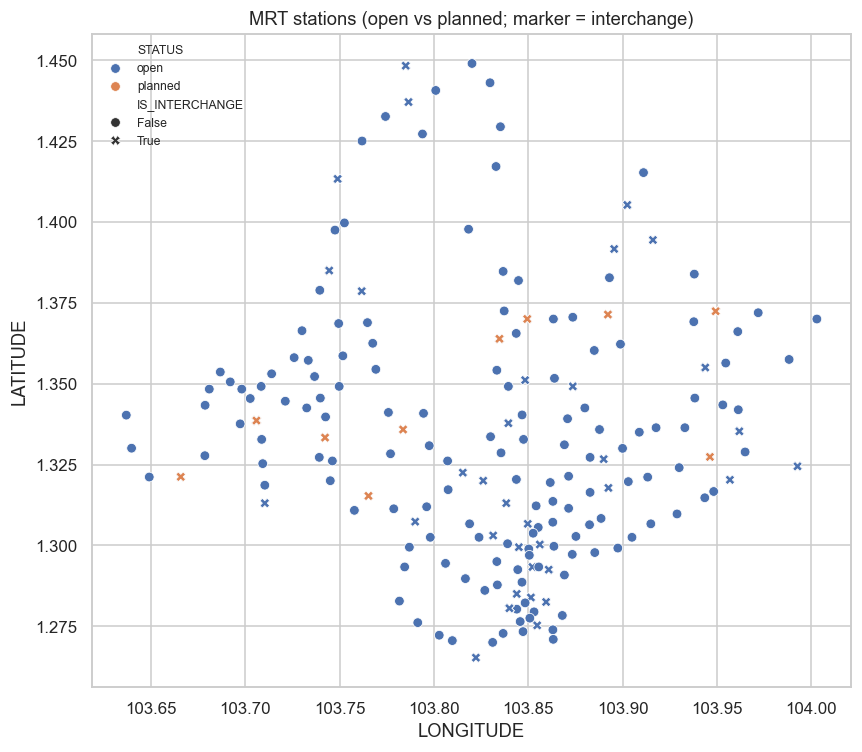

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=mrt, x="LONGITUDE", y="LATITUDE", hue="STATUS",
    style="IS_INTERCHANGE", s=40, ax=ax,
)
ax.set_title("MRT stations (open vs planned; marker = interchange)")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [12]:
interchanges = (
    mrt.groupby("NAME")["LINE"].nunique().loc[lambda s: s > 1].sort_values(ascending=False)
)
print(f"{len(interchanges)} interchange names (serve >1 line)")
interchanges.head(10).to_frame("n_lines")


44 interchange names (serve >1 line)


,n_lines
NAME,
marina bay mrt station,3
choa chu kang mrt/lrt station,3
jurong east mrt station,3
outram park mrt station,3
pasir ris mrt station,3
dhoby ghaut mrt station,3
punggol mrt/lrt station,3
newton mrt station,2
orchard mrt station,2


MRT planning areas are a superset of HDB ones: stations also sit in industrial / downtown slivers
with little or no HDB housing (`tuas`, `boon lay`, `orchard`, …). Those areas will not attach to
rental rows.


## 7. Area-level connectivity features

Counts are of station-line rows unless noted. `n_interchange_stations` counts unique names in the
area that serve more than one line anywhere on the network.


In [13]:
mrt_features = mrt.groupby("PLANNING_AREA").agg(
    n_mrt_open=("STATUS", lambda s: s.eq("open").sum()),
    n_mrt_planned=("STATUS", lambda s: s.eq("planned").sum()),
    n_distinct_lines=("LINE", "nunique"),
).reset_index()
interchange_by_area = (
    mrt.loc[mrt["IS_INTERCHANGE"]]
    .groupby("PLANNING_AREA")["NAME"]
    .nunique()
    .rename("n_interchange_stations")
)
mrt_features = mrt_features.merge(interchange_by_area, on="PLANNING_AREA", how="left")
mrt_features["n_interchange_stations"] = mrt_features["n_interchange_stations"].fillna(0).astype(int)
mrt_features["n_mrt_total"] = mrt_features["n_mrt_open"] + mrt_features["n_mrt_planned"]
mrt_features.sort_values("n_mrt_total", ascending=False).head(10)


,PLANNING_AREA,n_mrt_open,n_mrt_planned,n_distinct_lines,n_interchange_stations,n_mrt_total
11,downtown core,19,0,5,6,19
1,bedok,11,1,4,2,12
14,jurong east,9,1,5,2,10
37,tampines,10,0,4,2,10
12,geylang,10,0,3,2,10
15,jurong west,8,1,3,1,9
28,queenstown,9,0,2,1,9
5,bukit merah,9,0,4,1,9
16,kallang,8,0,5,0,8
40,toa payoh,8,0,4,1,8


## 8. Summary

- **Grain:** one row = one station on one line. 243 rows, 192 names, 51 extra rows are interchanges.
- **Status:** 231 open, 12 planned. Keep both in this table. Split them in the area counts.
  The 1 km feature uses open names only.
- **Quality:** no missing values, no out-of-bounds coordinates, `CODE` is unique. `PLANNING_AREA`
  / `REGION` spelling matches the HDB crosswalk on every overlapping area.
- **Join path:** `PLANNING_AREA` via the HDB crosswalk, not a direct key onto `train.csv`.
- **Next:** `01_eda_school.ipynb`, then `03_feature_rmse.ipynb`.


In [14]:
mrt.to_csv(CLEANED / "sg_mrt_stations_cleaned.csv", index=False)
mrt_features.to_csv(OUT / "mrt_features_by_area.csv", index=False)
print("wrote", CLEANED / "sg_mrt_stations_cleaned.csv", mrt.shape)
print("wrote", OUT / "mrt_features_by_area.csv", mrt_features.shape)


wrote ../cleaned/sg_mrt_stations_cleaned.csv (243, 10)
wrote ../outputs/mrt_features_by_area.csv (45, 6)
